<a href="https://colab.research.google.com/github/narayn02/Projects/blob/main/Student_performance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Model evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

**Upload And Loadd Dataset**

In [16]:
from google.colab import files

uploaded = files.upload()

Saving student_data.csv to student_data (2).csv


In [17]:
# Load the uploaded CSV file
df = pd.read_csv("student_data.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 395
Number of columns: 33


In [18]:
df.head()
print("Columns in the dataset:\n")

for column in df.columns:
    print(column)

Columns in the dataset:

school
sex
age
address
famsize
Pstatus
Medu
Fedu
Mjob
Fjob
reason
guardian
traveltime
studytime
failures
schoolsup
famsup
paid
activities
nursery
higher
internet
romantic
famrel
freetime
goout
Dalc
Walc
health
absences
G1
G2
G3


In [19]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


**Check Missing And Duplicate Value**

In [20]:
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values)

Missing values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [21]:
# Count duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())
# Remove duplicate records
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Number of duplicate rows: 0
Dataset shape after removing duplicates: (395, 33)


**Eplore Student Grades**

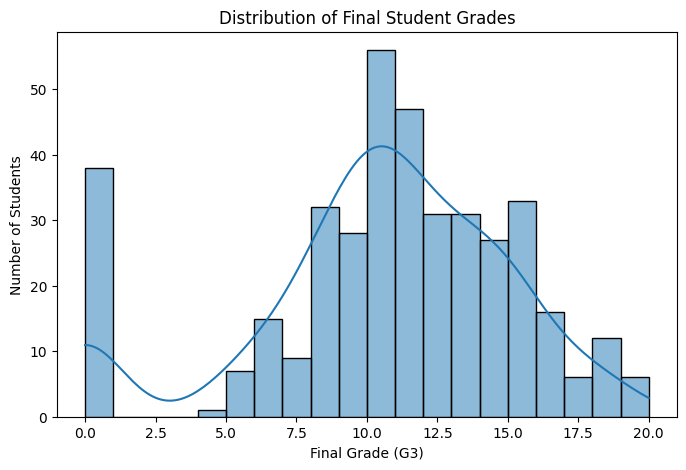

In [22]:
plt.figure(figsize=(8, 5))

sns.histplot(df["G3"], bins=20, kde=True)

plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.title("Distribution of Final Student Grades")

plt.show()

**G1,G2 And G3 Comparison**

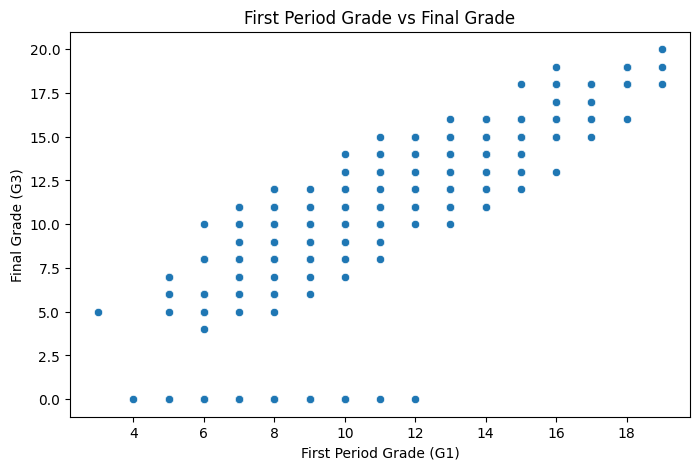

In [23]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="G1", y="G3")

plt.xlabel("First Period Grade (G1)")
plt.ylabel("Final Grade (G3)")
plt.title("First Period Grade vs Final Grade")

plt.show()

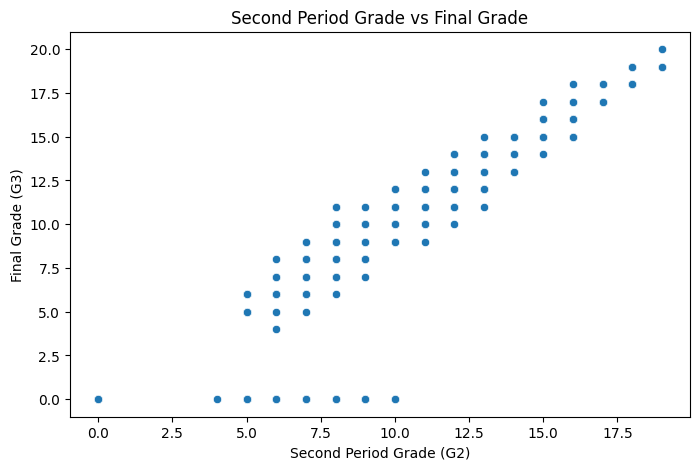

In [24]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="G2", y="G3")

plt.xlabel("Second Period Grade (G2)")
plt.ylabel("Final Grade (G3)")
plt.title("Second Period Grade vs Final Grade")

plt.show()

In [25]:
# Separate input features and target variable

X = df.drop("G3", axis=1)
y = df["G3"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (395, 32)
Target shape: (395,)


In [26]:
# Identify numerical columns
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Categorical columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


**Encode Categorical Data And Split Dataset**

In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    ],
    remainder="passthrough"
)

In [28]:
# 80% data for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 316
Testing records: 79


**Train The Linear Regression Model**

In [29]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [30]:
# Predict final grades for test students
y_pred = model.predict(X_test)

# Display the first 10 predictions
print("Predicted Final Grades:")
print(y_pred[:10])

Predicted Final Grades:
[ 6.00160699 11.52847844  2.86643677  8.79663116  8.55310627 11.88964112
 19.09674195  7.17307901  7.4050707  12.31153657]


In [31]:
comparison = pd.DataFrame({
    "Actual G3": y_test.values,
    "Predicted G3": y_pred
})

comparison.head(10)

,Actual G3,Predicted G3
0,10,6.001607
1,12,11.528478
2,5,2.866437
3,10,8.796631
4,9,8.553106
5,13,11.889641
6,18,19.096742
7,6,7.173079
8,0,7.405071
9,14,12.311537


**Evaluate The Machine Learning Model**

In [32]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("----------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R² Score:", round(r2, 2))

Model Evaluation
----------------------------
Mean Absolute Error (MAE): 1.65
Mean Squared Error (MSE): 5.66
Root Mean Squared Error (RMSE): 2.38
R² Score: 0.72


**Actual VS Predicted Graph**

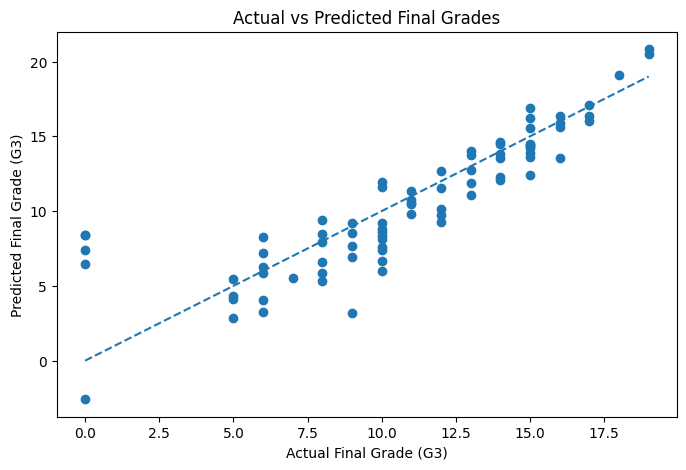

In [33]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Final Grade (G3)")
plt.ylabel("Predicted Final Grade (G3)")
plt.title("Actual vs Predicted Final Grades")

plt.show()

**Predict The Final Grade Of a New Student**

In [34]:
# Create information for a new student
new_student = pd.DataFrame({
    "school": ["GP"],
    "sex": ["F"],
    "age": [17],
    "address": ["U"],
    "famsize": ["GT3"],
    "Pstatus": ["T"],
    "Medu": [3],
    "Fedu": [3],
    "Mjob": ["teacher"],
    "Fjob": ["other"],
    "reason": ["course"],
    "guardian": ["mother"],
    "traveltime": [1],
    "studytime": [3],
    "failures": [0],
    "schoolsup": ["no"],
    "famsup": ["yes"],
    "paid": ["no"],
    "activities": ["yes"],
    "nursery": ["yes"],
    "higher": ["yes"],
    "internet": ["yes"],
    "romantic": ["no"],
    "famrel": [4],
    "freetime": [3],
    "goout": [3],
    "Dalc": [1],
    "Walc": [1],
    "health": [3],
    "absences": [4],
    "G1": [12],
    "G2": [13]
})

# Predict the final grade
predicted_grade = model.predict(new_student)

print("Predicted Final Grade (G3):", round(predicted_grade[0], 2))

Predicted Final Grade (G3): 12.84
